# ODMR Analysis



<div style="background-color:#4CAF50; padding:8px 14px; border-radius:4px;">
<h2 style="color:black; margin:0;">Import Libraries</h2>
</div>

In [23]:
import numpy as np
from pathlib import Path
import json
import matplotlib.pyplot as plt
from lmfit.models import LorentzianModel, PolynomialModel
from scipy.signal import find_peaks
#import ipywidgets as widgets
from IPython.display import display, clear_output
import pandas as pd
import re

<div style="background-color:#4CAF50; padding:8px 14px; border-radius:4px;">
<h2 style="color:black; margin:0;"> General Helpful Functions</h2>
</div>

In [29]:
def load_run(run_folder):
    data = np.load(run_folder / "odmr_data.npz")
    with open(run_folder / "metadata.json") as f:
        metadata = json.load(f)

    # drop fields we don't need to carry around
    skip_keys = {"experiment_id", "timestamp"}
    run = {k: v for k, v in metadata.items() if k not in skip_keys}

    run["frequencies"] = data["frequencies"]
    run["signal"] = data["signal"]
    run["reference"] = data["reference"]
    run["contrast"] = data["contrast"]
    run["run_folder"] = run_folder

    return run


def load_all_runs(parent_dir):
    parent_dir = Path(parent_dir)
    runs = {}
    for run_folder in sorted(parent_dir.iterdir()):
        if not run_folder.is_dir():
            continue
        match = re.match(r"^\d{14}_(\d+)$", run_folder.name)  # YYYYMMDDHHMMSS_runnumber
        if not match:  # skip anything that isn't a run folder
            continue
        run_number = int(match.group(1))
        runs[run_number] = load_run(run_folder)
    return runs
def plot_normalized_runs(runs, run_numbers, ax=None):
    if ax is None:
        fig, ax = plt.subplots()

    for run_number in run_numbers:
        run = runs[run_number]
        normalized_signal = run["signal"] / np.max(run["signal"])
        ax.plot(run["frequencies"], normalized_signal, label=f"run {run_number}")

    ax.set_xlabel("Frequency (MHz)")
    ax.set_ylabel("Normalized signal")
    ax.legend()
    return ax

def plot_raw_runs(runs, run_numbers, ax=None):
    if ax is None:
        fig, ax = plt.subplots()

    for run_number in run_numbers:
        run = runs[run_number]
        ax.plot(run["frequencies"], run["signal"], label=f"run {run_number}")

    ax.set_xlabel("Frequency (MHz)")
    ax.set_ylabel("Signal (counts per second)")
    ax.legend()
    return ax


def metadata_table(runs):
    skip = {"frequencies", "signal", "reference", "contrast", "run_folder"}  # data arrays, not metadata
    rows = {n: {k: v for k, v in run.items() if k not in skip} for n, run in runs.items()}
    return pd.DataFrame.from_dict(rows, orient="index").sort_index()

<div style="background-color:#4CAF50; padding:8px 14px; border-radius:4px;">
<h2 style="color:black; margin:0;">Load Data</h2>
</div>

In [30]:
parent_dir = "/Volumes/hlab-nas/Data/DefectMsmts/Data/Greenland/ODMR"
runs = load_all_runs(parent_dir)

print(list(runs.keys()))

[1, 2, 3, 4, 5, 6, 7, 8, 9, 11, 12, 13, 14]


In [7]:
print(runs[18].keys())

runs[22]["reps"]
runs[22]["laser_power"]
runs[18]["thickness"]

dict_keys(['laser_power', 'mw_gain', 'reps', 'ND Filter OD', 'relax_delay_treg', 'sweep_start_fGHz', 'sweep_stop_fGHz', 'sweep_step_fGHz', 'picture', 'thickness', 'frequencies', 'signal', 'reference', 'contrast', 'run_folder'])


'flake directly on waveguide'

In [9]:
table = metadata_table(runs)
print(table.to_string())

    laser_power  mw_gain   reps  ND Filter OD  relax_delay_treg  sweep_start_fGHz  sweep_stop_fGHz  sweep_step_fGHz
3            40     5000   1000           0.5               500                 3              4.0             0.01
4            40     5000   1000           0.5               500                 3              4.0             0.01
5            40     5000   1000           0.5               500                 2              5.0             0.01
6            40     5000  10000           0.5               500                 2              5.0             0.01
7            40     5000  10000           0.5               500                 2              5.0             0.01
8            40     5000   1000           0.5               500                 2              5.0             0.01
9            40     5000  10000           0.5               500                 2              5.0             0.01
10           40     5000   1000           0.5               500         

In [10]:
changing = table.loc[:, table.astype(str).nunique() > 1]
print(changing.to_string())

     reps  sweep_start_fGHz  sweep_stop_fGHz
3    1000                 3              4.0
4    1000                 3              4.0
5    1000                 2              5.0
6   10000                 2              5.0
7   10000                 2              5.0
8    1000                 2              5.0
9   10000                 2              5.0
10   1000                 2              5.0
11  10000                 2              5.0
12   1000                 2              5.0
13  10000                 2              5.0
14  10000                 2              5.0


<div style="background-color:#4CAF50; padding:8px 14px; border-radius:4px;">
<h2 style="color:black; margin:0;">Raw Data</h2>
</div>

<div style="background-color:#2196F3; padding:8px 14px; border-radius:4px;">
<h3 style="color:black; margin:0;"> Plot Raw Data</h3>
</div>


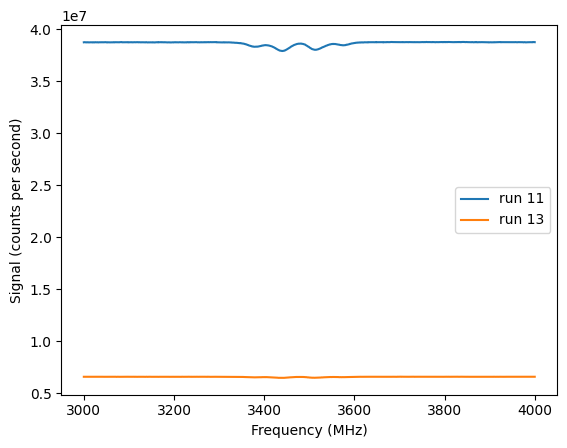

In [31]:

plot_raw_runs(runs, [11,13])
plt.show()

<div style="background-color:#2196F3; padding:8px 14px; border-radius:4px;">
<h3 style="color:black; margin:0;"> Normalized Plots</h3>
</div>


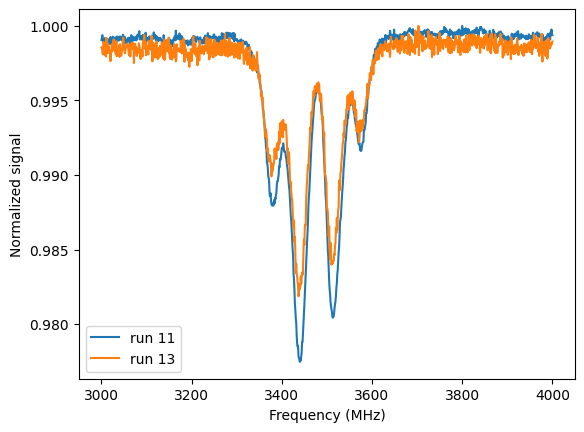

In [32]:
runs_1 = [11,13];
plot_normalized_runs(runs, runs_1)
plt.show()

<div style="background-color:#4CAF50; padding:8px 14px; border-radius:4px;">
<h2 style="color:black; margin:0;">Analysis</h2>
</div>

<div style="background-color:#2196F3; padding:8px 14px; border-radius:4px;">
<h3 style="color:black; margin:0;"> Fit Functions</h3>
</div>


In [51]:
def find_dip_centers(run, n_peaks=4, prominence=None, freq_range=None):
    """
    (same docstring as before, plus:)

    freq_range (tuple of float or None): optional (min_freq, max_freq)
        to restrict the search window, excluding known artifact
        regions outside the real resonance range.
    """
    frequencies = run["frequencies"]
    signal = run["signal"]

    if freq_range is not None:
        mask = (frequencies >= freq_range[0]) & (frequencies <= freq_range[1])
        frequencies = frequencies[mask]
        signal = signal[mask]

    inverted = -signal
    peak_indices, properties = find_peaks(inverted, prominence=prominence)

    if prominence is None:
        peak_indices, properties = find_peaks(inverted, prominence=1)

    prominences = properties["prominences"]
    top_idx = np.argsort(prominences)[::-1][:n_peaks]
    top_peak_indices = peak_indices[top_idx]

    centers = frequencies[top_peak_indices]
    return np.sort(centers)

def build_odmr_model(centers, signal, sigma_guess=15):

    """
    Build a composite lmfit model for an ODMR spectrum: a polynomial
    baseline plus one Lorentzian dip per given center frequency.

    How it works:
    - Starts with a 3rd-degree polynomial to represent the baseline
    (the smooth background the dips sit on top of).
    - Adds one LorentzianModel per entry in `centers`, each with its
    own labeled prefix (l1_, l2_, l3_, ...) so parameters can be
    referenced by name later (e.g. result.params["l1_center"]).
    - Each Lorentzian's center is bounded to within +/-15 of its guess,
    sigma (width) is bounded between 1 and 60, and amplitude is
    constrained negative so it fits as a dip rather than a peak.

    Parameters:
        centers (list of float): initial guess frequencies for each
            dip center, typically from find_dip_centers().
        signal (np.ndarray): the ODMR signal data, used to set a realistic
            starting value for the baseline constant term.
        sigma_guess (float): initial guess for each dip's width
            (default 15).

    Returns:
        model (lmfit.Model): the combined baseline + Lorentzians model.
        params (lmfit.Parameters): initial parameter guesses and bounds
            for the model, ready to be passed into model.fit().
    """

    model = PolynomialModel(degree=3, prefix="bkg_")
    params = model.make_params()

    # give the constant term a realistic starting value instead of 0
    params["bkg_c0"].set(value=np.median(signal))
    params["bkg_c1"].set(value=0)
    params["bkg_c2"].set(value=0)
    params["bkg_c3"].set(value=0)

    for i, center in enumerate(centers, start=1):
        prefix = f"l{i}_"
        lz = LorentzianModel(prefix=prefix)
        model = model + lz
        lz_params = lz.make_params()
        lz_params[f"{prefix}center"].set(value=center, min=center-15, max=center+15)
        lz_params[f"{prefix}sigma"].set(value=sigma_guess, min=1, max=60)
        lz_params[f"{prefix}amplitude"].set(value=-1e7, min=-1e9, max=0)
        params.update(lz_params)

    return model, params

def fit_run(run, centers):

    """
    Fit a single run's ODMR signal to the baseline + Lorentzians model.

    How it works:
    - Builds the model and initial parameters via build_odmr_model()
    using the given center guesses.
    - Fits that model to the run's raw signal as a function of frequency
    using lmfit's least-squares fitting.

    Parameters:
        run (dict): a single run's data dictionary, must contain
            "frequencies" and "signal" arrays.
        centers (list of float): initial guess frequencies for each
            dip center, typically from find_dip_centers().

    Returns:
        result (lmfit.ModelResult): the fit result object, containing
            fitted parameters, uncertainties, and fit diagnostics
            (access via result.fit_report(), result.params, etc.).
    """

    model, params = build_odmr_model(centers,run["signal"])
    result = model.fit(run["signal"], params, x=run["frequencies"])
    return result

def compute_contrast(result, frequencies, n_peaks=4):

    """
    Compute ODMR contrast from a fit result, defined as the average of
    the two deepest Lorentzian dips (each dip depth normalized by the
    local baseline value at that dip's center).

    How it works:
    - For each fitted Lorentzian, pulls its center and dip depth
    (height), then finds the baseline's fitted value at that same
    center frequency.
    - Normalizes each dip's depth by its local baseline value, giving
    a fractional contrast per line.
    - Sorts all dip contrasts and averages the two largest, since the
    two most prominent dips dominate the visible signal and averaging
    them improves SNR by a factor of sqrt(2) over using just one.

    Parameters:
        result (lmfit.ModelResult): fit result from fit_run().
        frequencies (np.ndarray): frequency array for the run (used to
            look up the baseline value nearest each dip's center).
        n_peaks (int): number of Lorentzians in the fit (default 4).

    Returns:
        contrast (float): average fractional contrast of the two
            deepest dips.
        depths (list of float): fractional contrast for all n_peaks
            dips, sorted largest to smallest.
    """

    depths = []
    centers = []
    for i in range(1, n_peaks + 1):
        prefix = f"l{i}_"
        center = result.params[f"{prefix}center"].value
        height = abs(result.params[f"{prefix}height"].value)
        baseline_val = result.eval_components()["bkg_"][np.argmin(np.abs(frequencies - center))]
        depths.append(height / baseline_val)
        centers.append(center)

    # contrast still uses the two deepest, regardless of order
    contrast = np.mean(sorted(depths, reverse=True)[:2])

    # but for display, sort everything by frequency (left to right)
    order = np.argsort(centers)
    centers = [centers[i] for i in order]
    depths = [depths[i] for i in order]

    return contrast, depths, centers


def plot_contrast_vs_run(runs, run_numbers, ax=None, freq_ranges=None):
    """
    (same docstring as before)
    """
    if ax is None:
        fig, ax = plt.subplots()

    freq_ranges = freq_ranges or {}
    contrasts = []
    for run_number in run_numbers:
        run = runs[run_number]
        freq_range = freq_ranges.get(run_number)
        centers = find_dip_centers(run, n_peaks=4, freq_range=freq_range)
        result = fit_run(run, centers)
        contrast, depths, dip_centers = compute_contrast(result, run["frequencies"])
        contrasts.append(contrast)

    bars = ax.bar([str(r) for r in run_numbers], contrasts)

    for bar, contrast in zip(bars, contrasts):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
                f"{contrast:.4f}", ha="center", va="bottom", fontsize=9)

    ax.set_xlabel("Run number")
    ax.set_ylabel("Contrast (avg of top 2 dips)")
    ax.set_title("Contrast vs. run number")

    return ax

def compute_dip_counts(result, n_peaks=4):
    depths = []
    centers = []
    for i in range(1, n_peaks + 1):
        prefix = f"l{i}_"
        centers.append(result.params[f"{prefix}center"].value)
        depths.append(abs(result.params[f"{prefix}height"].value))  # dip depth in cps

    dip_counts = np.mean(sorted(depths, reverse=True)[:2])  # avg of top 2 dips

    order = np.argsort(centers)  # sort by frequency for display
    centers = [centers[i] for i in order]
    depths = [depths[i] for i in order]

    return dip_counts, depths, centers

def plot_normalized_fits(runs, run_numbers, ax=None, freq_ranges=None):
    if ax is None:
        fig, ax = plt.subplots()

    freq_ranges = freq_ranges or {}
    info_lines = []

    for run_number in run_numbers:
        run = runs[run_number]
        freq_range = freq_ranges.get(run_number)
        centers = find_dip_centers(run, n_peaks=4, freq_range=freq_range)
        result = fit_run(run, centers)
        dip_counts, depths, dip_centers = compute_dip_counts(result)

        norm = np.max(run["signal"])
        line, = ax.plot(run["frequencies"], run["signal"] / norm, label=f"run {run_number}")
        ax.plot(run["frequencies"], result.best_fit / norm, linestyle="--",
                color=line.get_color(), alpha=0.5, linewidth=1)

        info_lines.append(f"run {run_number}: dip depth (avg top 2) = {dip_counts:.3e} cps")

    ax.set_xlabel("Frequency (MHz)")
    ax.set_ylabel("Normalized signal")
    ax.legend()

    info_text = "\n".join(info_lines)
    fig = ax.get_figure()
    fig.text(1.02, 0.5, info_text, transform=ax.transAxes, va="center", ha="left", fontsize=10)
    plt.tight_layout()

    return ax

def plot_enhancement(runs, run_numbers, norm_run, ax=None, freq_ranges=None):
    if ax is None:
        fig, ax = plt.subplots()

    freq_ranges = freq_ranges or {}
    if isinstance(norm_run, list):  # allows [13] or 13
        norm_run = norm_run[0]

    def get_dip_counts(run_number):
        run = runs[run_number]
        centers = find_dip_centers(run, n_peaks=4, freq_range=freq_ranges.get(run_number))
        result = fit_run(run, centers)
        dip_counts, depths, dip_centers = compute_dip_counts(result)
        return dip_counts

    norm_counts = get_dip_counts(norm_run)
    enhancements = [get_dip_counts(r) / norm_counts for r in run_numbers]

    bars = ax.bar([str(r) for r in run_numbers], enhancements)

    for bar, ef in zip(bars, enhancements):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
                f"{ef:.3f}", ha="center", va="bottom", fontsize=9)

    ax.axhline(1, color="gray", linestyle="--", alpha=0.5)  # EF = 1 is the norm
    ax.set_xlabel("Run number")
    ax.set_ylabel("Enhancement factor")
    ax.set_title(f"Enhancement vs. run (norm = run {norm_run})")

    return ax


<div style="background-color:#2196F3; padding:8px 14px; border-radius:4px;">
<h3 style="color:black; margin:0;"> Find Dips</h3>
</div>


[3376.99985619 3436.9998333  3509.99980545 3570.99978218]


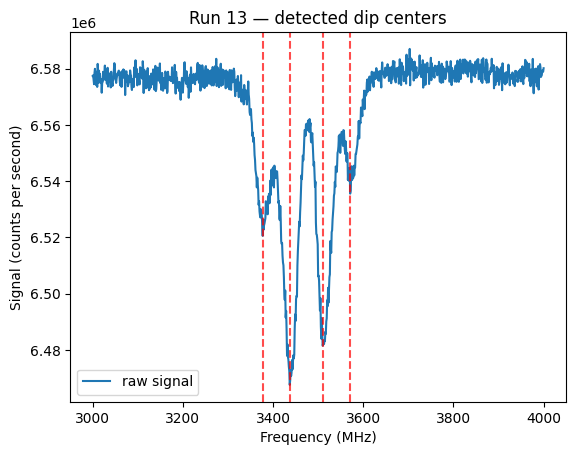

In [45]:
run_num = 13
centers = find_dip_centers(runs[run_num], n_peaks=4, freq_range=(3000, 4000))
print(centers)

fig, ax = plt.subplots()
ax.plot(runs[run_num]["frequencies"], runs[run_num]["signal"], label="raw signal")

for c in centers:
    ax.axvline(c, color="red", linestyle="--", alpha=0.7)

ax.set_xlabel("Frequency (MHz)")
ax.set_ylabel("Signal (counts per second)")
ax.set_title(f"Run {run_num} — detected dip centers")
ax.legend()
plt.show()

<div style="background-color:#2196F3; padding:8px 14px; border-radius:4px;">
<h3 style="color:black; margin:0;"> Lorentzian Fit</h3>
</div>


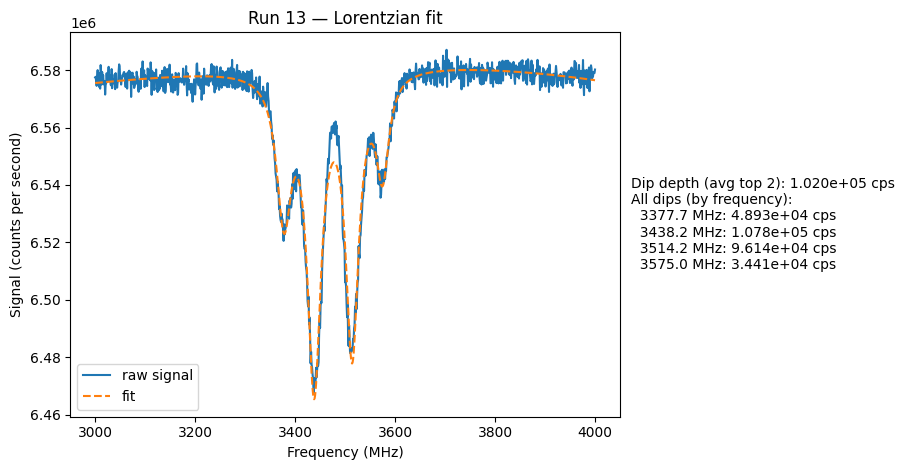

In [46]:
result = fit_run(runs[run_num], centers)
dip_counts, depths, centers = compute_dip_counts(result)

fig, ax = plt.subplots()
ax.plot(runs[run_num]["frequencies"], runs[run_num]["signal"], label="raw signal")
ax.plot(runs[run_num]["frequencies"], result.best_fit, label="fit", linestyle="--")
ax.set_xlabel("Frequency (MHz)")
ax.set_ylabel("Signal (counts per second)")
ax.set_title(f"Run {run_num} — Lorentzian fit")
ax.legend()

info_text = f"Dip depth (avg top 2): {dip_counts:.3e} cps\nAll dips (by frequency):\n"
info_text += "\n".join(f"  {c:.1f} MHz: {d:.3e} cps" for c, d in zip(centers, depths))

fig.text(1.02, 0.5, info_text, transform=ax.transAxes, va="center", ha="left", fontsize=10)

plt.tight_layout()
plt.show()

Save Plot

In [47]:
save_path = runs[run_num]["run_folder"] / "lorentzian_fit.png"
save_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(save_path, dpi=300, bbox_inches="tight")
print(f"Saved to {save_path}")

Saved to /Volumes/hlab-nas/Data/DefectMsmts/Data/Greenland/ODMR/20261109010545_013/lorentzian_fit.png


<div style="background-color:#2196F3; padding:8px 14px; border-radius:4px;">
<h3 style="color:black; margin:0;"> Multiple</h3>
</div>


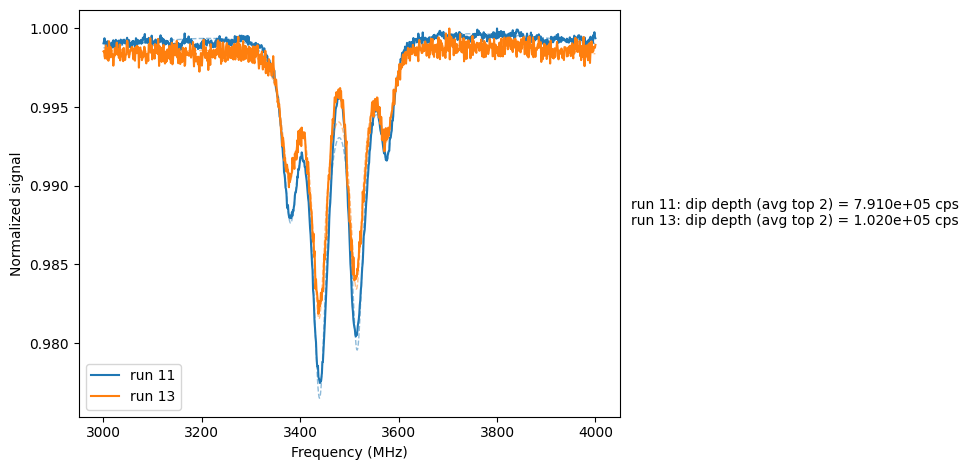

In [50]:
plot_normalized_fits(runs, [11,13], freq_ranges={24: (3000, 4000)})
plt.show()

<div style="background-color:#2196F3; padding:8px 14px; border-radius:4px;">
<h3 style="color:black; margin:0;"> Comparisons</h3>
</div>


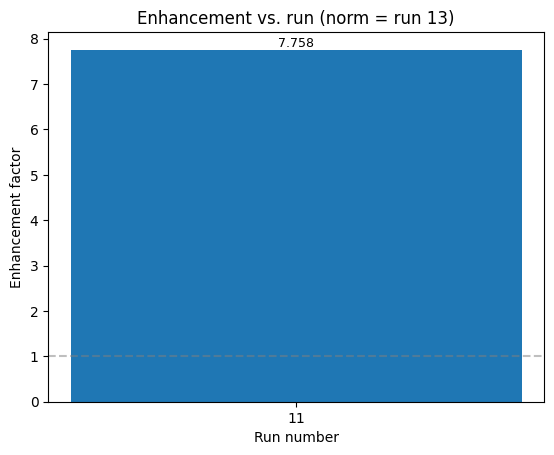

In [52]:
plot_enhancement(runs, [11], [13], freq_ranges={24: (3000, 4000)})
plt.show()

<div style="background-color:#4CAF50; padding:8px 14px; border-radius:4px;">
<h2 style="color:black; margin:0;">Interactive</h2>
</div>